# Image Fourier

## Imports


In [2]:
import   numpy   as np
import   matplotlib.pyplot     as  plt
from   scipy.fft   import   fft2, fftshift, ifft2
from   skimage.util    import  invert
from   skimage.draw    import  ellipse, disk
from   skimage.transform     import   rotate
from skimage import io, data, restoration
from skimage.util import img_as_ubyte, img_as_float


## 1 Frequencies


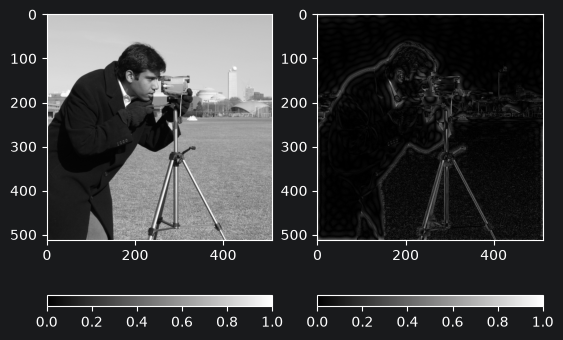

In [ ]:
im  =  img_as_float(data.camera())
r  = 20
imw  =  np.zeros_like(im)
cx, cy   =  np.round(np.array(im.shape)/2)
rr, cc   =  disk((cx, cy), r, shape=im.shape)
imw[rr, cc]    =  1
imfft   = fftshift(fft2(im))
imfft[imw>0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
plt.clim(0,    1)
ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
plt.clim(0,    1)


## 2 Visualization

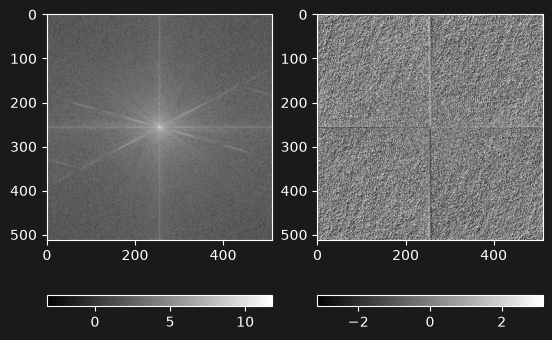

In [ ]:
im  =  img_as_float(data.camera())
imfft   = fftshift(fft2(im))
imm  =  np.log(np.abs(imfft))
ima  =  np.angle(imfft)
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(imm, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(ima, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Frequency Components


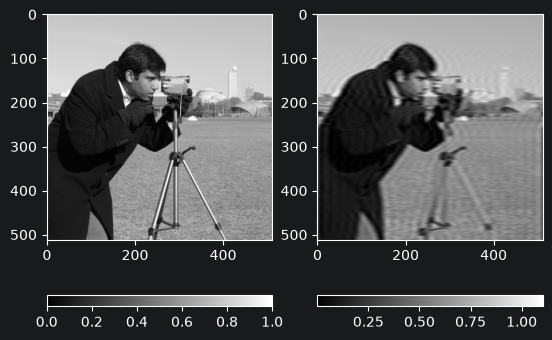

In [ ]:
im  = img_as_float(data.camera())
imfft   = fftshift(fft2(im))
cx, cy   = np.round(np.array(im.shape)/2)
rx  = np.round(np.array(im.shape[0])/2)
ry  = np.round(np.array(im.shape[1])/20)
rot  =  np.deg2rad(0)
rr, cc   = ellipse(cx, cy, rx, ry, rotation=rot)
imw  =  np.zeros_like(im)
imw[rr, cc]    =  1
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  = fig.add_subplot(1,      2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  = fig.add_subplot(1,      2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Frequency Components


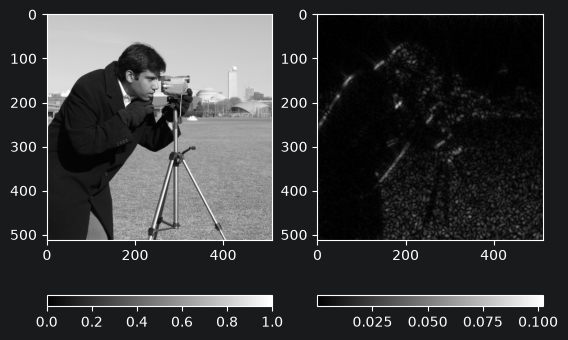

In [ ]:
imfft   = fftshift(fft2(im))
cx, cy   =  np.round(np.array(im.shape)/4)
r  = np.round(np.array(im.shape[1])/10)
rr, cc   =  disk((cx, cy), r, shape=im.shape)
imw  =  np.zeros_like(im)
imw[rr, cc]    =  1
rr, cc   =  disk((3*cx,    3*cy), r, shape=im.shape)
imw[rr, cc]    =  1
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## 3 Frequency Components


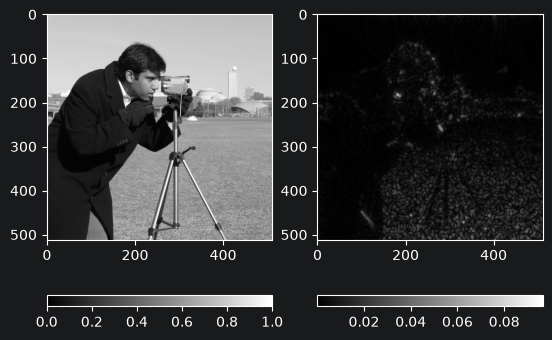

In [ ]:
imfft   = fftshift(fft2(im))
cx, cy   =  np.round(np.array(im.shape)/4)
r  = np.round(np.array(im.shape[1])/10)
rr, cc   =  disk((3*cx, cy), r, shape=im.shape)
imw  =  np.zeros_like(im)
imw[rr, cc]    =  1
rr, cc   =  disk((cx,   3*cy), r, shape=im.shape)
imw[rr, cc]    =  1
imfft[imw==0]     = 0
imf  =  np.abs(ifft2(imfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     2,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     2,  2)
p  = plt.imshow(imf, cmap='gray')
c  = plt.colorbar(orientation='horizontal')


## # Low -frequencies


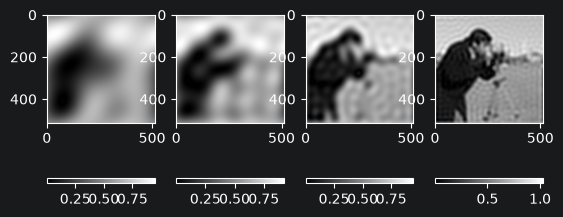

In [ ]:
im  =  img_as_float(data.camera())
fig  =  plt.figure()
r  = np.array([3,     5,  10,  20])
for  i  in  range(0, r.shape[0]):
   imw  = np.zeros_like(im)
   cx, cy   = np.round(np.array(im.shape)/2)
   rr, cc   = disk((cx, cy), r[i], shape=im.shape)
   imw[rr, cc]    =  1
   imfft  =  fftshift(fft2(im))
   imfft[imw==0]     = 0
   imf  = np.abs(ifft2(imfft))
   ax  = fig.add_subplot(1, r.shape[0], i+1)
   p =  plt.imshow(imf, cmap='gray')
   c =  plt.colorbar(orientation='horizontal')


## 4 High -frequencies


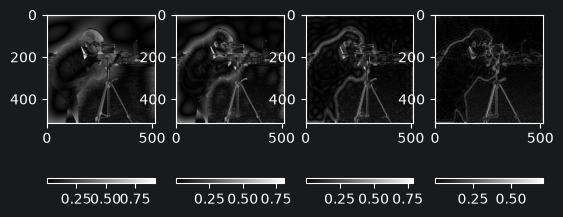

In [ ]:
im  =  img_as_float(data.camera())
fig  =  plt.figure()
r  = np.array([3,     5, 10,  20])
for  i  in  range(0, r.shape[0]):
   imw  = np.zeros_like(im)
   cx, cy   = np.round(np.array(im.shape)/2)
   rr, cc   = disk((cx, cy), r[i], shape=im.shape)
   imw[rr, cc]    = 1
   imfft  =  fftshift(fft2(im))
   imfft[imw==1]    =  0
   imf  = np.abs(ifft2(imfft))
   ax  = fig.add_subplot(1, r.shape[0], i+1)
   p =  plt.imshow(imf, cmap='gray')
   c =  plt.colorbar(orientation='horizontal')


## 5 DTF Example


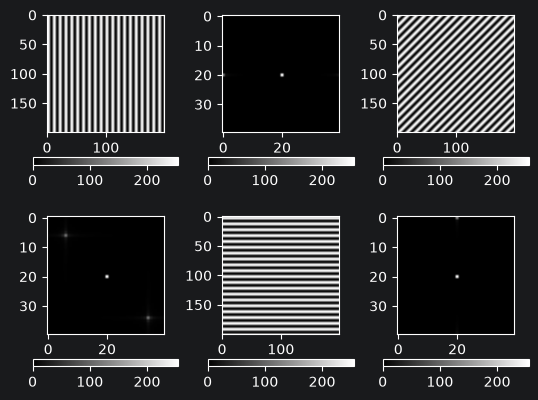

In [ ]:
def  normalize(x):
   return  (x  -  x.min())   / (x.max()    - x.min())
im  = img_as_float(data.camera())
xs  = np.linspace(-2*np.pi,       2*np.pi,   200)
ys  = np.linspace(-2*np.pi,       2*np.pi,   200)
fig  =  plt.figure()
a  = np.array([0,    45,  90])
a  = np.deg2rad(a)
for  i  in range(0,a.shape[0]):
   x, y  = np.meshgrid(xs, ys)
   x =  x *  np.cos(a[i])    + y  * np.sin(a[i])
   y =  -x *  np.sin(a[i])    +  y *  np.cos(a[i])
   f =  10
   imp  = np.sin(f*x)
   imp  = normalize(imp+np.abs(imp.min()))
   imfft  =  fftshift(fft2(imp))
   imm  = np.abs(imfft)
   imp  = img_as_ubyte(normalize(imp))
   imm  = img_as_ubyte(normalize(imm))
   ax =  fig.add_subplot(2, a.shape[0], (2*i)+1)
   p =  plt.imshow(imp, cmap='gray')
   c =  plt.colorbar(orientation='horizontal')
   ax =  fig.add_subplot(2, a.shape[0], (2*i)+2)
   p =  plt.imshow(imm[80:120,      80:120], cmap='gray')
   c =  plt.colorbar(orientation='horizontal')


## 6 DTF Example - 2


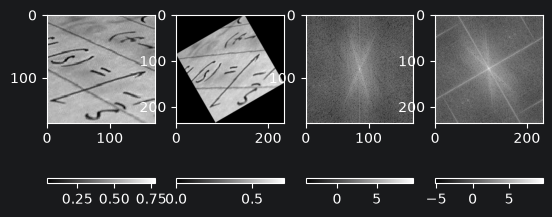

In [ ]:
im  =  img_as_float(data.text())
im  =  im[0:172,   0:172]
imr  =  rotate(im,    30, resize=True)
imfft   = fftshift(fft2(im))
imm  =  np.log(np.abs(imfft))
imrfft   =  fftshift(fft2(imr))
imrm   = np.log(np.abs(imrfft))
fig  =  plt.figure()
ax  =  fig.add_subplot(1,     4,  1)
p  = plt.imshow(im, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     4,  2)
p  = plt.imshow(imr, cmap='gray')
c  = plt.colorbar(orientation='horizontal')
ax  =  fig.add_subplot(1,     4,  3)
p =  plt.imshow(imm, cmap='gray')
c =  plt.colorbar(orientation='horizontal')
ax =  fig.add_subplot(1,      4, 4)
p =  plt.imshow(imrm, cmap='gray')
c =  plt.colorbar(orientation='horizontal')
